# Rolling 12-month IPCA forecast errors

This notebook evaluates one **12-month-ahead Focus forecast per month**, rather than one forecast for each calendar year. For month M, it takes the last available Focus observation in M with `Suavizada = 'N'` and `baseCalculo = 0`. At month-end, the first IPCA month not yet published is M, so the forecast covers M through M+11. The realized outcome is `100 × (IBGE index at M+11 / IBGE index at M−1 − 1)`. This is **compounded 12-month inflation**, not the arithmetic average of 12 monthly rates.

The BCB explains the non-smoothed 12-month forecast in its [Focus methodology, questions 14–15](https://www.bcb.gov.br/content/controleinflacao/Documents/Expectativas_mercado/FAQ13-Expectativas-de-Mercado.pdf). The realized index comes from [IBGE SIDRA table 1737, variable 2266](https://apisidra.ibge.gov.br/values/t/1737/n1/all/v/2266/p/200110-202512), saved locally on November 2, 2026. The database snapshot is identified by `dados/atual.json`.

## 1. Load the local Focus snapshot and IBGE index

Run the notebook from the repository root or from `projects/`. The IBGE CSV is versioned; the Focus SQLite snapshot must be available locally.

In [8]:
suppressPackageStartupMessages({
  library(DBI)
  library(RSQLite)
  library(jsonlite)
})

project_root <- if (file.exists('dados/atual.json')) {
  '.'
} else if (file.exists('../dados/atual.json')) {
  '..'
} else {
  stop('Cannot find dados/atual.json; run from the repository root or projects/.')
}
snapshot <- fromJSON(file.path(project_root, 'dados/atual.json'))
ibge <- read.csv(file.path(project_root, 'projects/data/ibge_ipca_monthly_index_200110_202512.csv'),
                 colClasses = c('character', 'numeric'))
expected_index_months <- format(seq(as.Date('2001-10-01'), as.Date('2025-12-01'), by = 'month'), '%Y%m')
stopifnot(identical(ibge$month, expected_index_months),
          all(is.finite(ibge$ipca_index)), all(ibge$ipca_index > 0))
cat('Focus snapshot:', snapshot$coleta, '\n')
cat('IBGE index months:', nrow(ibge), '\n')

Focus snapshot: 20261029T204913Z 
IBGE index months: 291 


## 2. Select the last non-smoothed forecast in each month

The selected Focus date must be no more than seven days before month-end. This avoids silently using a stale forecast. The analysis starts with November 2001, the first month with available observations in this Focus series, and ends with January 2025, whose 12-month outcome ends in December 2025.

In [ ]:
con <- dbConnect(SQLite(), file.path(project_root, snapshot$banco))
focus <- tryCatch(dbGetQuery(con, '
  WITH ranked AS (
    SELECT substr(Data, 1, 7) AS forecast_month,
           Data AS forecast_date,
           Mediana AS forecast_ipca_12m_pct,
           DesvioPadrao AS disagreement_pp,
           numeroRespondentes AS respondents,
           ROW_NUMBER() OVER (PARTITION BY substr(Data, 1, 7) ORDER BY Data DESC) AS rn
    FROM ExpectativasMercadoInflacao12Meses
    WHERE Indicador = ? AND Suavizada = ? AND baseCalculo = ?
      AND Data >= ? AND Data < ?
  )
  SELECT forecast_month, forecast_date, forecast_ipca_12m_pct,
         disagreement_pp, respondents,
         CAST(julianday(date(forecast_month || "-01", "+1 month", "-1 day"))
              - julianday(forecast_date) AS INTEGER) AS days_before_month_end,
         strftime("%Y%m", date(forecast_month || "-01", "-1 month")) AS index_before_window,
         strftime("%Y%m", date(forecast_month || "-01", "+11 months")) AS outcome_end_month
  FROM ranked WHERE rn = 1 ORDER BY forecast_month
', params = list('IPCA', 'N', 0L, '2001-11-01', '2025-02-01')),
finally = dbDisconnect(con))
expected_forecast_months <- format(seq(as.Date('2001-11-01'), as.Date('2025-01-01'), by = 'month'), '%Y-%m')
stopifnot(identical(focus$forecast_month, expected_forecast_months),
          !anyNA(focus$forecast_ipca_12m_pct), !anyNA(focus$disagreement_pp),
          all(focus$days_before_month_end >= 0 & focus$days_before_month_end <= 7))
cat('Monthly forecasts:', nrow(focus), '\n')
head(focus, 3)

Monthly forecasts: 279 


,forecast_month,forecast_date,forecast_ipca_12m_pct,disagreement_pp,respondents,days_before_month_end,index_before_window,outcome_end_month
,<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>
1,2001-11,2001-11-30,5.67,0.59,NA,0,200110,200210
2,2001-12,2001-12-31,4.77,0.57,NA,0,200111,200211
3,2002-01,2002-01-31,4.83,0.37,NA,0,200112,200212


## 3. Match each forecast to realized inflation

The IBGE index immediately **before** the forecast month is the denominator; the index 11 months **after** the forecast month is the numerator. The signed error is `Focus forecast − realized inflation` in percentage points. A positive error means overprediction.

In [4]:
start_row <- match(focus$index_before_window, ibge$month)
end_row <- match(focus$outcome_end_month, ibge$month)
stopifnot(!anyNA(start_row), !anyNA(end_row))
focus$realized_ipca_12m_pct <- 100 * (ibge$ipca_index[end_row] / ibge$ipca_index[start_row] - 1)
focus$error_pp <- focus$forecast_ipca_12m_pct - focus$realized_ipca_12m_pct
focus$absolute_error_pp <- abs(focus$error_pp)
stopifnot(round(focus$realized_ipca_12m_pct[1], 2) == 8.45,
          round(tail(focus$realized_ipca_12m_pct, 1), 2) == 4.26)

selected <- focus[c('forecast_month', 'forecast_date', 'outcome_end_month',
                    'forecast_ipca_12m_pct', 'realized_ipca_12m_pct',
                    'error_pp', 'absolute_error_pp', 'disagreement_pp')]
print(head(selected, 6), row.names = FALSE, digits = 4)
print(tail(selected, 6), row.names = FALSE, digits = 4)

 forecast_month forecast_date outcome_end_month forecast_ipca_12m_pct
        2001-11    2001-11-30            200210                  5.67
        2001-12    2001-12-31            200211                  4.77
        2002-01    2002-01-31            200212                  4.83
        2002-02    2002-02-28            200301                  4.72
        2002-03    2002-03-28            200302                  4.92
        2002-04    2002-04-30            200303                  4.92
 realized_ipca_12m_pct error_pp absolute_error_pp disagreement_pp
                 8.445   -2.775             2.775            0.59
                10.933   -6.163             6.163            0.57
                12.530   -7.700             7.700            0.37
                14.467   -9.747             9.747            0.33
                15.847  -10.927            10.927            0.38
                16.573  -11.653            11.653            0.40
 forecast_month forecast_date outcome_end_month 

## 4. Summarize the errors

Consecutive outcomes overlap by 11 months, so the 279 errors are **not independent observations**. Descriptive statistics below should not be treated as confidence intervals.

In [5]:
summary_rolling <- data.frame(
  months = nrow(focus),
  mean_signed_error_pp = mean(focus$error_pp),
  mean_absolute_error_pp = mean(focus$absolute_error_pp),
  median_absolute_error_pp = median(focus$absolute_error_pp),
  rmse_pp = sqrt(mean(focus$error_pp^2))
)
print(summary_rolling, row.names = FALSE, digits = 4)


 months mean_signed_error_pp mean_absolute_error_pp median_absolute_error_pp
    279               -1.036                  1.809                    1.127
 rmse_pp
   2.879


## 5. Forecast, realized IPCA, and error

The x-axis is the **forecast month**. The realized line shows inflation in the subsequent 12-month window, which was not known at the forecast date. The lower panel is forecast minus realized IPCA in percentage points.

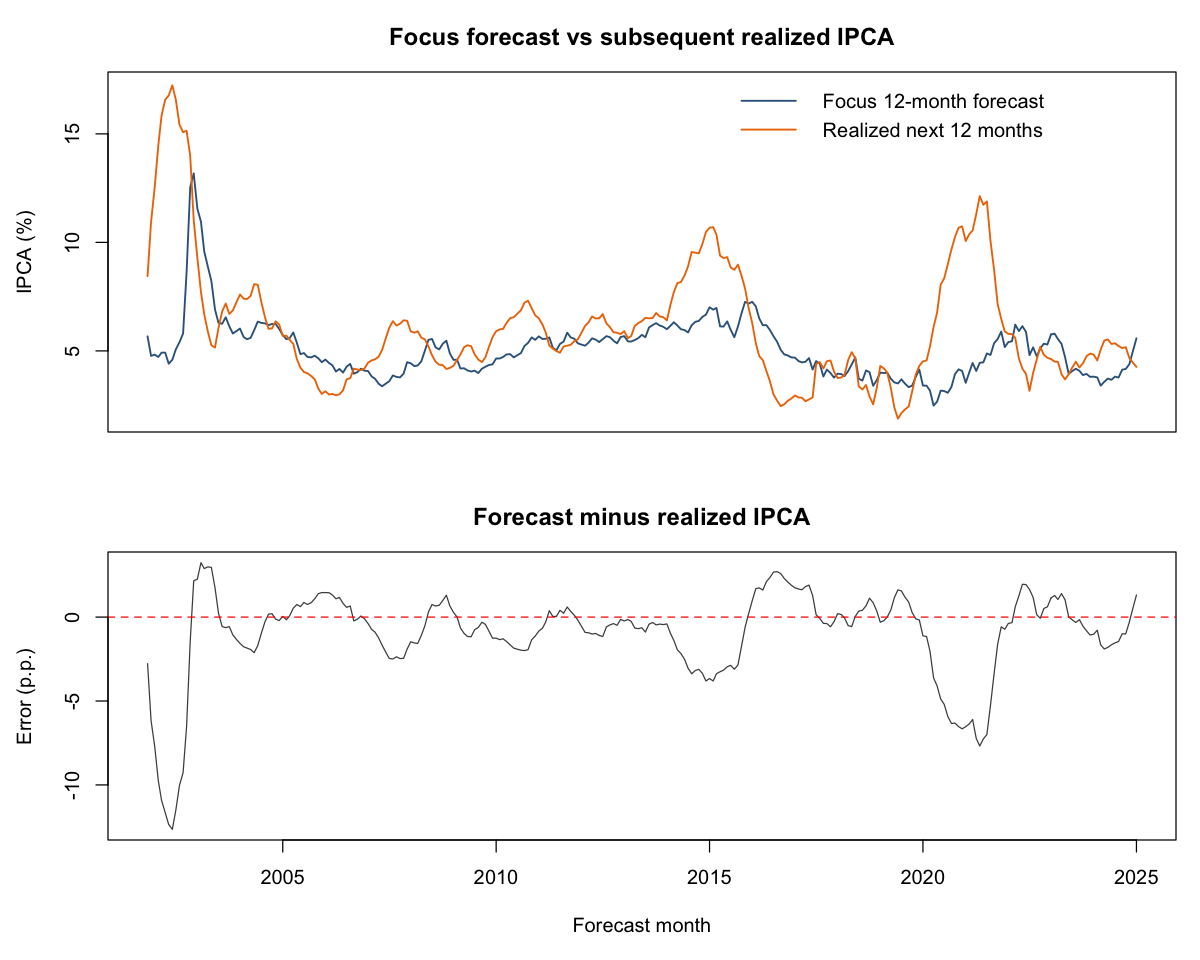

In [6]:
plot_month <- as.Date(paste0(focus$forecast_month, '-01'))
options(repr.plot.width = 10, repr.plot.height = 8)
old_par <- par(no.readonly = TRUE)
par(bg = 'white', mfrow = c(2, 1), mar = c(2, 4.5, 3, 1))

plot(plot_month, focus$forecast_ipca_12m_pct, type = 'l',
     col = 'steelblue4', lwd = 1.5, xaxt = 'n', xlab = '',
     ylim = range(c(focus$forecast_ipca_12m_pct, focus$realized_ipca_12m_pct)),
     ylab = 'IPCA (%)', main = 'Focus forecast vs subsequent realized IPCA')
lines(plot_month, focus$realized_ipca_12m_pct, col = 'darkorange2', lwd = 1.5)
legend('topright', c('Focus 12-month forecast', 'Realized next 12 months'),
       col = c('steelblue4', 'darkorange2'), lty = 1, lwd = 1.5, bty = 'n')

par(mar = c(5, 4.5, 3, 1))
plot(plot_month, focus$error_pp, type = 'l', col = 'grey30',
     xlab = 'Forecast month', ylab = 'Error (p.p.)',
     main = 'Forecast minus realized IPCA')
abline(h = 0, col = 'red', lty = 2)
par(old_par)

## 6. Distribution of signed errors

Negative values indicate underprediction; positive values indicate overprediction. The histogram shows the observed distribution but does not account for overlap between adjacent forecast windows.

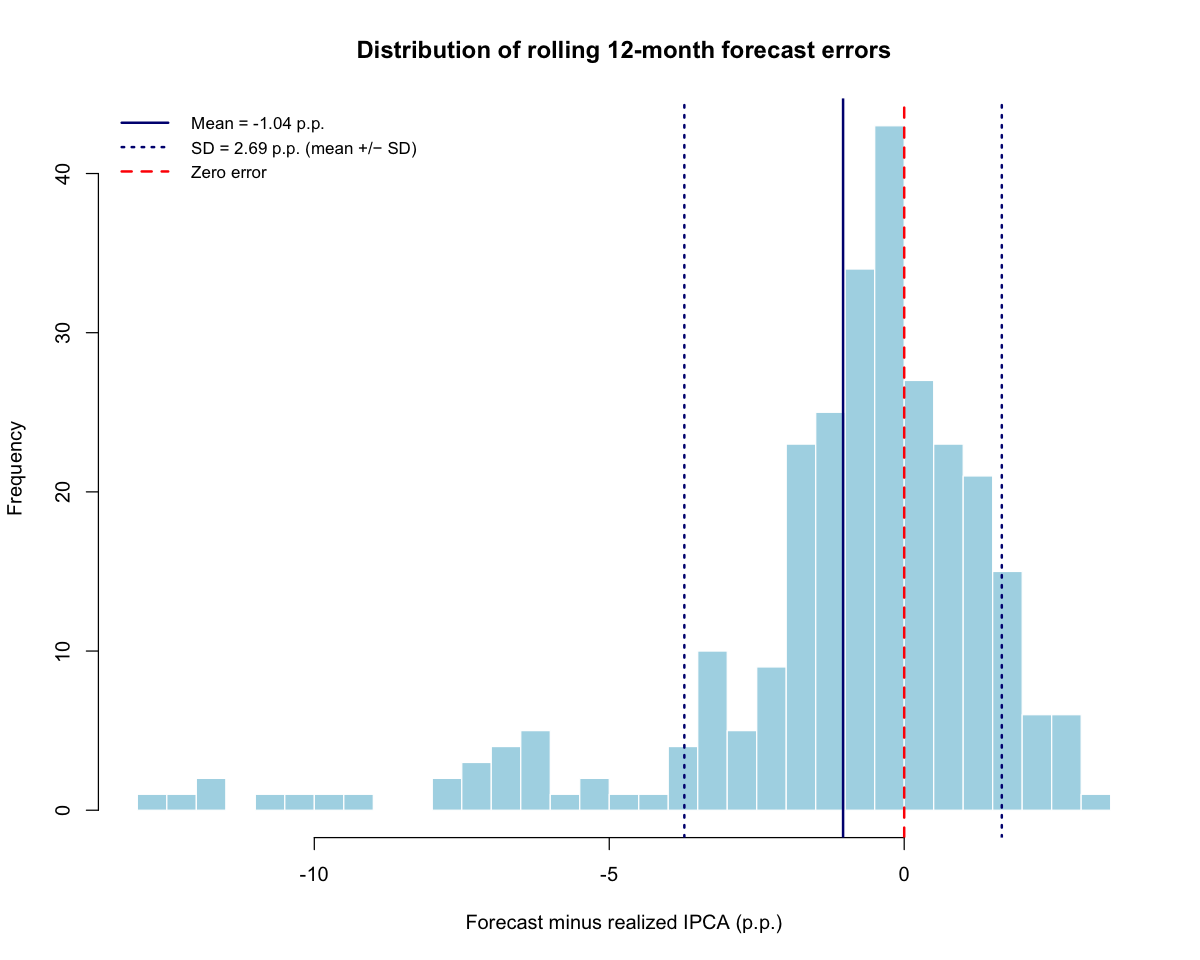

In [7]:
mean_error <- mean(focus$error_pp)
sd_error <- sd(focus$error_pp)

par(bg = 'white')
hist(focus$error_pp, breaks = 25, col = 'lightblue', border = 'white',
     main = 'Distribution of rolling 12-month forecast errors',
     xlab = 'Forecast minus realized IPCA (p.p.)')
abline(v = 0, col = 'red', lty = 2, lwd = 2)
abline(v = mean_error, col = 'navy', lwd = 2)
abline(v = mean_error + c(-sd_error, sd_error), col = 'navy', lty = 3, lwd = 2)
legend('topleft',
       legend = c(sprintf('Mean = %.2f p.p.', mean_error),
                  sprintf('SD = %.2f p.p. (mean +/− SD)', sd_error),
                  'Zero error'),
       col = c('navy', 'navy', 'red'), lty = c(1, 3, 2), lwd = 2,
       bty = 'n', cex = 0.85)


### Empirical CDF of signed errors

The CDF gives the share of forecast months with signed error at or below each value on the horizontal axis. The marked value at zero is the share with error at or below zero. This equals the underprediction share here because there are no exact-zero errors. Negative values are underpredictions; positive values are overpredictions.


In [ ]:
signed_error_ecdf <- ecdf(focus$error_pp)
share_at_zero <- signed_error_ecdf(0)
stopifnot(abs(share_at_zero - mean(focus$error_pp <= 0)) < 1e-12)

options(repr.plot.width = 10, repr.plot.height = 6)
par(bg = 'white')
plot(signed_error_ecdf, do.points = FALSE, verticals = TRUE,
     col = 'steelblue4', lwd = 2,
     xlab = 'Forecast minus realized IPCA (p.p.)',
     ylab = 'Share of forecast months with error <= x',
     main = 'Empirical CDF of signed 12-month forecast errors')
abline(v = 0, col = 'red', lty = 2, lwd = 2)
abline(h = share_at_zero, col = 'grey45', lty = 3)
points(0, share_at_zero, pch = 19, col = 'red')
legend('topleft', sprintf('At zero: %d/%d months (%.1f%%)',
                              sum(focus$error_pp <= 0), nrow(focus),
                              100 * share_at_zero), bty = 'n')


**Validated snapshot result:** the CDF at zero is **180/279 = 64.5%**. Since none of these errors equals zero, this is also the share of months in which Focus underpredicted realized 12-month IPCA.

![Empirical CDF of signed rolling 12-month forecast errors](figures/ipca_rolling_12m_signed_error_ecdf.png)


## 7. Direction of the 12-month errors

A negative signed error means Focus **underpredicted** the next 12 months of IPCA; a positive error means it overpredicted. Count both directions alongside the mean and median signed error. Because the 12-month outcome windows overlap, these counts describe the observed months and are not independent trials.


In [ ]:
direction_counts <- c(underprediction = sum(focus$error_pp < 0),
                      exact = sum(focus$error_pp == 0),
                      overprediction = sum(focus$error_pp > 0))
stopifnot(sum(direction_counts) == nrow(focus))
direction_summary <- data.frame(
  direction = names(direction_counts),
  months = as.integer(direction_counts),
  share_pct = 100 * as.integer(direction_counts) / nrow(focus)
)
print(direction_summary, row.names = FALSE, digits = 4)
cat(sprintf('Mean signed error: %.3f p.p.; median: %.3f p.p.\n',
            mean(focus$error_pp), median(focus$error_pp)))


## 8. Distribution of relative forecast accuracy

Define the **absolute relative error** as `100 × |forecast − realized| / |realized|`. A forecast is **95% close** when this error is at most 5% (between 95% and 105% of realized IPCA), and **90% close** when it is at most 10% (between 90% and 110%). This symmetric rule does not reward arbitrarily large overpredictions. These are descriptive tolerances, not 90% or 95% statistical confidence intervals.

The ECDF shows the share of months below every relative-error threshold; vertical markers show the 5% and 10% cutoffs. The left panel enlarges the threshold region; the right panel shows the complete distribution.


In [ ]:
stopifnot(all(is.finite(focus$realized_ipca_12m_pct)),
          all(abs(focus$realized_ipca_12m_pct) > 1e-8))
focus$signed_relative_error_pct <- 100 * focus$error_pp / abs(focus$realized_ipca_12m_pct)
focus$absolute_relative_error_pct <- abs(focus$signed_relative_error_pct)
thresholds_pct <- c(5, 10)
close_counts <- vapply(thresholds_pct, function(tolerance) {
  sum(focus$absolute_relative_error_pct <= tolerance)
}, integer(1))
closeness <- data.frame(
  label = c('95% close (within +/-5%)', '90% close (within +/-10%)'),
  tolerance_pct = thresholds_pct,
  months = close_counts,
  share_pct = 100 * close_counts / nrow(focus)
)
print(closeness, row.names = FALSE, digits = 4)

options(repr.plot.width = 12, repr.plot.height = 5)
old_par <- par(no.readonly = TRUE)
par(bg = 'white', mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))
error_ecdf <- ecdf(focus$absolute_relative_error_pct)
for (zoom in c(TRUE, FALSE)) {
  plot(error_ecdf, do.points = FALSE, verticals = TRUE,
       xlim = if (zoom) c(0, 20) else c(0, max(focus$absolute_relative_error_pct)),
       ylim = if (zoom) c(0, 0.5) else c(0, 1),
       col = 'steelblue4', lwd = 2,
       xlab = 'Absolute relative error (% of realized IPCA)',
       ylab = 'Share of forecast months',
       main = if (zoom) 'Detail: 0–20% error' else 'Complete distribution')
  abline(v = thresholds_pct, col = c('darkgreen', 'darkorange3'), lty = 2, lwd = 2)
  points(thresholds_pct, close_counts / nrow(focus),
         col = c('darkgreen', 'darkorange3'), pch = 19)
}
par(old_par)
cat(sprintf('At 5%%: %d/%d months (%.1f%%); at 10%%: %d/%d months (%.1f%%).\n',
            close_counts[1], nrow(focus), closeness$share_pct[1],
            close_counts[2], nrow(focus), closeness$share_pct[2]))


**Validated snapshot result:** 180 of 279 rolling forecasts underpredicted realized IPCA and 99 overpredicted it. Mean signed error was **−1.036 p.p.**; median signed error was **−0.461 p.p.**. **38/279 (13.6%)** forecasts were within ±5% of realized inflation and **76/279 (27.2%)** were within ±10%.

![Empirical CDF of rolling 12-month absolute relative forecast error, including 5% and 10% thresholds](figures/ipca_rolling_12m_relative_error_ecdf.png)
